# Scratch space for BuzzWatch tracking 


## Imports

In [1]:
import os 
import sys
import pickle

import cv2 as cv
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import linear_sum_assignment
from dataclasses import dataclass, field
from collections import defaultdict


## Tracking params class

In [125]:
# tracking parameters
@dataclass
class TrackerParams:
    # Crop: fraction of frame width to remove from each side (left & right)
    # Adjust based on your chamber setup — from the example frame ~0.18 works.
    crop_left_frac: float = 0.05  # 0.18
    crop_right_frac: float = 0.05  # 0.2

    # # Background subtraction
    new_thresh_weight: float = 0.15  # weight for per-frame otsu thresh in smoothing
    old_thresh_weight: float = 0.85  # weight for previous thresh in smoothing
    # bg_history: int = 200          # frames used to build background model
    # bg_var_threshold: float = 16   # sensitivity; lower = more sensitive

    # Blob filtering (in pixels, after crop)
    min_area: int = 15           # ignore noise smaller than this
    max_area: int = 1000  #800              # ignore large artifacts / clumps
    min_circularity: float = 0.0      # 0.0 = no constraint; raise to filter elongated debris
    invert_frame: bool = True         # do we need to invert frame? True for dark flies on light backround
    detect_flies_open_size: int = 0   # size of array for morpho opening of binarized image
    detect_flies_close_size: int = 7  # size of array for morpho closing of binarized image
    detect_flies_blur_size: int = 3   # size of array for gaussian blur prior to thresholding
    
    # Tracker assignment
    max_distance: float = 100.0     # px — detections further than this start a new track
    max_missing_frames: int = 20   # frames a track can go undetected before being dropped

    # Kalman filter noise — key tuning parameters.
    # The ratio between these determines how much weight the filter gives
    # to the motion model vs. the raw detector output.
    kalman_process_noise: float = 100   #1e-2 # raise for more erratic / faster insects
    kalman_measurement_noise: float = 10  #1e-1 # raise if detector centroids are jittery
    
    # Output
    draw_trails: bool = True
    trail_length: int = 40         # how many past positions to draw
    output_video: bool = True      # write annotated output video


## Tracks class

In [126]:
def make_kalman(params):
    """
    4D state vector: [x, y, vx, vy]
    2D measurement:  [x, y]

    Assumes constant-velocity motion between frames, which is a reasonable
    prior for insects in free flight. The filter corrects this estimate
    each time a real detection is assigned.
    """
    kf = cv.KalmanFilter(4, 2)  # 4 state dims, 2 measurement dims

    # # x' = x + vx,  y' = y + vy  (one timestep = one frame)
    # kf.transitionMatrix = np.array([
    #     [1, 0, 1, 0],
    #     [0, 1, 0, 1],
    #     [0, 0, 1, 0],
    #     [0, 0, 0, 1],
    # ], dtype=np.float32)

    # TEMP - hack way to get rid of Kalman(?)
    # x' = x + vx,  y' = y + vy  (one timestep = one frame)
    kf.transitionMatrix = np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 0, 1],
    ], dtype=np.float32)
    
    # We observe x and y directly (not velocity)
    kf.measurementMatrix = np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0],
    ], dtype=np.float32)

    kf.processNoiseCov     = np.eye(4, dtype=np.float32) * params.kalman_process_noise
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * params.kalman_measurement_noise
    kf.errorCovPost        = np.eye(4, dtype=np.float32)

    return kf

In [127]:
# storage for tracks
@dataclass
class Track:
    track_id: int
    params: TrackerParams
    positions: list = field(default_factory=list)
    missing_for: int = 0
    kf: cv.KalmanFilter = field(init=False)

    def __post_init__(self):
        self.kf = make_kalman(self.params)

    def init_kalman(self, cx: int, cy: int):
        """Seed the filter state with the first detection. Call once on spawn."""
        self.kf.statePost = np.array([[cx], [cy], [0.0], [0.0]], dtype=np.float32)

    def predict(self) -> tuple[int, int]:
        """
        Advance the filter by one timestep and return the predicted position.
        Must be called exactly once per frame, before assignment.
        Even for unmatched tracks (missing insects) we still call predict so
        the filter's internal state stays in sync with the frame clock.
        """
        pred = self.kf.predict()
        return int(pred[0]), int(pred[1])

    def update(self, cx: int, cy: int):
        """
        Feed a real detection into the filter (the 'correct' step).
        The filter blends the predicted position with the measurement,
        weighted by their respective noise covariances.
        """
        measurement = np.array([[cx], [cy]], dtype=np.float32)
        corrected = self.kf.correct(measurement)
        # Store the corrected position (smoother than raw detection,
        # more accurate than bare prediction)
        self.positions.append((int(corrected[0]), int(corrected[1])))
        self.missing_for = 0

    @property
    def last_pos(self) -> tuple[int, int]:
        return self.positions[-1]

## Helper functions

In [128]:
def otsu_is_reliable(diff_blurred, threshold, min_valley_depth=0.3):
    hist = cv.calcHist([diff_blurred], [0], None, [256], [0, 256]).flatten()
    hist = hist / hist.sum()  # normalize
    t = int(threshold)
    # Check that there's an actual valley near the threshold
    valley = hist[max(0, t-10):t+10].min()
    peak_left  = hist[:t].max()
    peak_right = hist[t:].max() if t < 255 else 0
    ratio = valley / max(peak_left, peak_right, 1e-6)
    return ratio < min_valley_depth  # low ratio = clear valley = reliable

In [129]:
def crop_frame(frame, params):  # -> tuple[np.ndarray, int]
    """
    Remove left/right portions of the frame. Returns (cropped, x_offset).

    Args:
        frame: input image (array) with x and y coordinates as the first two dimensions
        params: TrackerParams class with crop_left_frac and crop_right_frac as fields 
            (these represent the left and right fraction of image to crop)

    Returns: a 2-element tuple with elements:
        1st: the cropped image 
        2nd: the number of pixels cropped from the left
    """
    h, w = frame.shape[:2]
    x0 = int(w * params.crop_left_frac)
    x1 = int(w * (1 -  params.crop_right_frac))
    return frame[:, x0:x1], x0

In [130]:
def save_frame_from_video(vid_path, out_path=None, frame_number=100):
    """
    Convenience function to save a single frame from a video, given a file path

    Args:
        vid_path: full path to video, ideally .mp4 file
        out_path: folder to save image to. If None, save in same
            location as video file
        frame_number: int, which frame to take image from 
            (the first frame of first video often looks weird)
      
    Returns:
        frame_gray: grayscale image
    """
    # get path to save to
    if out_path is None:
        out_path = Path(vid_path).parent 
    if not isinstance(out_path, os.PathLike):
        out_path = Path(out_path)
    out_path.mkdir(exist_ok=True)

    # full filename to save to 
    out_path_full = out_path / (Path(vid_path).stem + '.png')
    
    # video capture
    cap = cv.VideoCapture(str(vid_path))
    cap.set(cv.CAP_PROP_POS_FRAMES, frame_number)  #
    
    # read single frame
    ret, frame = cap.read()

    # convert to gray
    frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    # save
    cv.imwrite(str(out_path_full), frame_gray)
    
    return frame_gray

In [131]:
def image_rolling_median(images, window_size=50):
    """
    Convenience function for taking the rolling median of an array of images

    Args:
        images: TxNxM array of images, where NxM is the image size and T corresponds to video index
        window_size: size for rolling median filter (total window ends up 2*window_size + 1)

    Returns:
        median_images: TxNxM array of median images
    """
    # initialize storage for median images
    median_images = list()
    
    # loop over images
    n_images = images.shape[0]
    for ith in np.arange(n_images):
        # get median for current position
        if ith <= window_size:
            median_img = np.median(images[0:(2*window_size), :, :], axis=0)
        elif window_size < ith < (n_images - window_size):
            median_img = np.median(images[(ith - window_size):(ith + window_size), :, :], axis=0)
        elif (n_images - window_size) <= ith < n_images:
            median_img = np.median(images[(-2*window_size):-1, :, :], axis=0)

        # append to list
        median_images.append(median_img)

    # return as np array
    return np.asarray(median_images)
    

In [132]:
def detect_flies(frame, bg, params, thresh_previous=None):
    """
    Function to detect dark objects (flies) on a bright background. 
    Assumes we have an estimate for static background

    ***For dark flies on a light background, need to take inverse of background***

    Args:
        frame: input image. should be cropped and ideally grayscale
        bg: background image
        params: TrackerParams class
        thresh_previous: previous value of threshold used to binarize foreground
            image. If none, just go with pure Otsu method
        
    Returns:
        centroids: a list of (x,y) coordinates of detected object centroids
        fg_mask: binary foreground image from which objects are detected
        thresh: threshold value used to binarize foreground image. Used to 
            keep a smooth running value and avoid bad frames

    TODO:
        - procedure for detecting/splitting merged flies
    """
    # convert to grayscale, if needed
    if frame.ndim > 2:
        frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    else:
        frame_gray = frame

    if bg.ndim > 2:
        bg = cv.cvtColor(bg, cv.COLOR_BGR2GRAY)
        
    # invert, if needed
    if params.invert_frame:
        frame_gray = cv.bitwise_not(frame_gray)

    # rescale frame to have same pixel intensity range as bg
    # should do this smarter though -- pick some x,y coords, do a fit between image intensity values
    # frame_gray = cv.normalize(frame_gray, None, np.min(bg), np.max(bg), cv.NORM_MINMAX)
    
    # subtract off static background
    fg =  cv.subtract(frame_gray, bg)  #  cv.absdiff(frame_gray, bg)  #
    
    # blur and binarize
    blur_size = params.detect_flies_blur_size
    fg_blur = cv.GaussianBlur( fg, (blur_size,blur_size),0)
    thresh_otsu, _ = cv.threshold(fg_blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

    # smooth threshold based on previous frames
    if thresh_previous is not None:
        thresh = params.old_thresh_weight*thresh_previous + params.new_thresh_weight*thresh_otsu
    else:
        thresh = thresh_otsu

    _, fg_mask = cv.threshold(fg_blur,thresh,255,cv.THRESH_BINARY)

    # print(thresh)
    # reliable = otsu_is_reliable(fg_blur, th)
    # print(th)
    # if not reliable:
    #     print(f'Otsu is NOT reliable')
    
    # morphological opening to remove noise
    open_size = params.detect_flies_open_size
    if open_size > 0:
        fg_mask = cv.morphologyEx(fg_mask, cv.MORPH_OPEN, np.ones((open_size, open_size), np.uint8))

    # morphological closing to merge fragmented pieces
    close_size = params.detect_flies_close_size
    if close_size > 0:
        fg_mask = cv.morphologyEx(fg_mask, cv.MORPH_CLOSE, np.ones((close_size, close_size), np.uint8))
    
    # locate objects
    contours, _ = cv.findContours(fg_mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # loop over detected objects to get centroids
    centroids = []
    for cnt in contours:
        area = cv.contourArea(cnt)
        if not (params.min_area <= area <= params.max_area):
            continue

        if params.min_circularity > 0:
            perimeter = cv.arcLength(cnt, True)
            if perimeter == 0:
                continue
            circularity = 4 * np.pi * area / (perimeter ** 2)
            if circularity < params.min_circularity:
                continue

        M = cv.moments(cnt)
        if M["m00"] == 0:
            continue
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        centroids.append((cx, cy))

    return centroids, fg_mask, thresh


In [133]:
def assign_detections_to_tracks(tracks, detections, predicted_positions, params):  # -> tuple[dict[int, int], list[int], list[int]]
    """
    Returns:
      matches      : {track_index: detection_index}
      unmatched_tracks : list of track indices with no detection this frame
      unmatched_dets   : list of detection indices that don't match any track
    """
    if not tracks or not detections:
        return {}, list(range(len(tracks))), list(range(len(detections)))

    track_pos = np.array(predicted_positions, dtype=float)   # (T, 2)
    det_pos   = np.array(detections, dtype=float)     # (D, 2)

    # Cost matrix: Euclidean distance
    diff = track_pos[:, None, :] - det_pos[None, :, :]  # (T, D, 2)
    cost = np.linalg.norm(diff, axis=2)                  # (T, D)

    row_ind, col_ind = linear_sum_assignment(cost)

    matches = {}
    unmatched_tracks = set(range(len(tracks)))
    unmatched_dets   = set(range(len(detections)))

    for r, c in zip(row_ind, col_ind):
        if cost[r, c] <= params.max_distance:
            matches[r] = c
            unmatched_tracks.discard(r)
            unmatched_dets.discard(c)

    return matches, list(unmatched_tracks), list(unmatched_dets)

In [134]:
COLORS = [
    (255, 80,  80),  (80, 200, 80),  (80, 80, 255),  (255, 200, 0),
    (0, 200, 255),   (255, 0, 200),  (180, 255, 80),  (255, 140, 0),
]

def color_for_id(track_id):
    """
    Args:
        track_id: int, identity of track
    Returns:
        3-tuple giving color
    """
    return COLORS[track_id % len(COLORS)]
    

In [135]:
def draw_frame(vis, tracks, detections, predicted_positions, params,frame_idx):
    """
    Function to visualize detected tracks

    """
    if vis.ndim == 2:
        vis = cv.cvtColor(vis, cv.COLOR_GRAY2BGR)

    # Raw detections (small grey dots)
    for cx, cy in detections:
        cv.circle(vis, (cx, cy), 3, (180, 180, 180), -1)

    for i, track in enumerate(tracks):
        color = color_for_id(track.track_id)

        # if track.missing_for > 0:
        #     # Draw predicted position as a hollow circle to indicate uncertainty
        #     if i < len(predicted_positions):
        #         px, py = predicted_positions[i]
        #         cv.circle(vis, (px, py), 5, color, 1)
        #     continue

        positions = track.positions[-params.trail_length:]
        abs_positions = [(x , y) for x, y in positions]

        # Trail (fades toward older positions)
        if params.draw_trails and len(abs_positions) > 1:
            for j in range(1, len(abs_positions)):
                alpha = j / len(abs_positions)
                faded = tuple(int(c * alpha) for c in color)
                cv.line(vis, abs_positions[j - 1], abs_positions[j], faded, 1)

        # Current corrected position (filled circle)
        cx, cy = abs_positions[-1]
        cv.circle(vis, (cx, cy), 5, color, -1)
        cv.putText(
            vis, str(track.track_id),
            (cx + 6, cy - 4),
            cv.FONT_HERSHEY_SIMPLEX, 0.38, color, 1, cv.LINE_AA,
        )

    cv.putText(
        vis, f"Frame {frame_idx}  Active tracks: {sum(1 for t in tracks if t.missing_for == 0)}",
        (10, 20), cv.FONT_HERSHEY_SIMPLEX, 0.5, (220, 220, 220), 1, cv.LINE_AA,
    )
    return vis

## Read video data

In [136]:
# path to data
# vid_path = r"D:\buzzwatch_videos\01_testing\cage_01\batch_02_aedes_test"
# vid_fn = "Cage_01_video_20260201_132308_0061.mp4"
vid_root = r"D:\buzzwatch_videos"
analysis_root = r"D:\buzzwatch_analysis"
experiment = "20260806"
cage = None  # "cage_01"
batch = None  # "batch_03_drosophila_test"  # batch_02_aedes_test
vid_fn = "video_20260806_185605_0045.mp4"

vid_path_full = Path(vid_root)

if experiment is not None:
    vid_path_full /= experiment 
if cage is not None:
    vid_path_full /= cage
if batch is not None:
    vid_path_full /= batch

vid_path_full /= vid_fn
    
vid_path_full

WindowsPath('D:/buzzwatch_videos/20260806/video_20260806_185605_0045.mp4')

In [137]:
# read with opencv(?)
test_play_flag = False

if test_play_flag:
    cap = cv.VideoCapture(str(vid_path_full))
     
    while cap.isOpened():
        ret, frame = cap.read()
        
        # if frame is read correctly ret is True
        if not ret:
            print("Can't receive frame (stream end?). Exiting ...")
            break
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
     
        cv.imshow('frame', gray)
        # if (cv.waitKey(1) == ord('q'):
        key = cv.waitKey(1) & 0xFF
        if key == 27:  # close on ESC
            break
     
    cap.release()
    cv.destroyAllWindows()


## Get backgrounds across experiment

Here I'm mimicking the BuzzWatch analysis app, getting a single frame from each video chunk and then taking a rolling median over these per-video images to get an estimate of the background

In [138]:
get_bg_flag = False

if get_bg_flag: 
    # first get a single frame for each video chunk
    vid_path = vid_path_full.parent 
    
    # get video chunk filenames
    vid_ext = '.mp4'
    vid_filenames = sorted(list(vid_path.glob(f'*{vid_ext}')))
    
    # where to save single images
    image_path = vid_path / "single_frames"
    image_path.mkdir(exist_ok=True)
    
    # loop over video chunks and get single frames
    frames = list()
    for fn in vid_filenames:
        print(f'Getting single frame for {fn}')
        img = save_frame_from_video(fn, out_path=image_path)
        frames.append(img)

    # where to save background images
    background_path = vid_path / 'backgrounds'
    background_path.mkdir(exist_ok=True)
    
    # get median of images
    frames = np.asarray(frames)

    print('Calculating median frames...')
    median_frames = image_rolling_median(frames, window_size=20)
    print('Done calculating median frames')
    
    # save background images 
    for ith, f in enumerate(vid_filenames):
        f_stem = f.stem
        bg_save_path = background_path / (f_stem + '.png')
        print(f'Saving background to {str(bg_save_path)}')
        cv.imwrite(str(bg_save_path), np.squeeze(median_frames[ith]))

    del frames 
    del median_frames

In [139]:
# try to get background for a single video
single_vid_bg_flag = False

if single_vid_bg_flag:
    bg_images = list()
    cap = cv.VideoCapture(str(vid_path_full))
    frame_number = 500

    # loop over video to grab images
    while cap.isOpened():
        cap.set(cv.CAP_PROP_POS_FRAMES, frame_number)
        ret, frame = cap.read()
        
        # if frame is read correctly ret is True
        if not ret:
            print("Can't receive frame (stream end?). Exiting ...")
            break
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

        
        bg_images.append(gray)
        print(f'Grabbing image from frame {frame_number}')
        
        frame_number += 1000

    cap.release()

    # take median of the images we got
    bg_images = np.asarray(bg_images)
    bg = np.median(bg_images, axis=0)

    # plot
    plt.imshow(bg, cmap='gray', vmin=0, vmax=255)

    # show
    bg_test_save_path = vid_path_full.parent / 'backgrounds_test' / (vid_path_full.stem + '.png')
    cv.imwrite(str(bg_test_save_path), np.squeeze(bg))

## Try analysis of single video

In [140]:
# play video with static bg subtracted
cap = cv.VideoCapture(str(vid_path_full))

# visualize?
viz_flag = True

# initialize storage for tracks
tracks: list[Track] = []
next_id = 0
all_trajectories: dict[int, list] = defaultdict(list)  # id -> [(frame, cx, cy)]
frame_idx = 0

# tracking params
# if params is None:
params = TrackerParams()
thresh_previous = None  

# load background image
vid_path = vid_path_full.parent
bg_path_full = vid_path / "backgrounds" / vid_fn.replace('.mp4', '.png')
print(bg_path_full)
bg = cv.imread(str(bg_path_full))
bg_gray = cv.cvtColor(bg, cv.COLOR_BGR2GRAY)
bg_gray_inv = cv.bitwise_not(bg_gray)
bg_gray_inv_crop, _ = crop_frame(bg_gray_inv, params)

# windows for display
if viz_flag:
    cv.namedWindow("frame", cv.WINDOW_NORMAL)
    cv.namedWindow("bg subtracted", cv.WINDOW_NORMAL)

while cap.isOpened():
    # read frame
    ret, frame = cap.read()
    
    # if frame is read correctly ret is True
    if not ret:
        print("Can't receive frame (stream end?). Exiting ...")
        break

    # crop
    frame_crop, _ = crop_frame(frame, params)

    # detect flies
    detections, fg_mask, thresh = detect_flies(frame_crop, bg_gray_inv_crop, params, 
                                               thresh_previous=None)  # thresh_previous=thresh_previous
    thresh_previous = thresh
    # make kalman predictions
    predicted_positions = [t.predict() for t in tracks]
    
    # Assignment
    matches, unmatched_tracks, unmatched_dets = assign_detections_to_tracks(
        tracks, detections, predicted_positions, params
    )

    # --- Kalman correct step for matched tracks ---
    for ti, di in matches.items():
        tracks[ti].update(*detections[di])  # correct() is called inside update()
        all_trajectories[tracks[ti].track_id].append(
            (frame_idx, tracks[ti].last_pos[0], tracks[ti].last_pos[1])
        )
        
    # Update matched tracks
    for ti, di in matches.items():
        tracks[ti].positions.append(detections[di])
        tracks[ti].missing_for = 0
        all_trajectories[tracks[ti].track_id].append(
            (frame_idx, detections[di][0], detections[di][1])
        )

    # Age unmatched tracks
    for ti in unmatched_tracks:
        tracks[ti].missing_for += 1

    # Spawn new tracks for unmatched detections
    for di in unmatched_dets:
        new_track = Track(track_id=next_id, params=params)
        new_track.init_kalman(*detections[di])
        new_track.positions.append(detections[di])
        tracks.append(new_track)
        all_trajectories[next_id].append(
            (frame_idx, detections[di][0], detections[di][1])
        )
        next_id += 1

    # Prune dead tracks
    tracks = [t for t in tracks if t.missing_for <= params.max_missing_frames]
    print(aaaa)
    # VISUALIZE?
    if viz_flag:
        # # draw centroids on image
        # for (cx, cy) in centroids:
        #     cv.circle(frame_crop, (cx, cy), 3, (0, 0, 255), -1)
        viz = draw_frame(frame_crop.copy(), tracks, detections, predicted_positions, params, frame_idx)
        # display image
        cv.imshow('frame', viz)
        cv.imshow('bg subtracted', fg_mask)
        
        # if (cv.waitKey(1) == ord('q'):
        key = cv.waitKey(1) & 0xFF
        if key == 27:  # close on ESC
            break

    frame_idx += 1
    if frame_idx % 100 == 0:
        print(f"  Processed {frame_idx} frames, {next_id} total tracks spawned")
 
cap.release()
cv.destroyAllWindows()

D:\buzzwatch_videos\20260806\backgrounds\video_20260806_185605_0045.png


C:\Users\samcw\AppData\Local\Temp\ipykernel_26408\1729796900.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return int(pred[0]), int(pred[1])
C:\Users\samcw\AppData\Local\Temp\ipykernel_26408\1729796900.py:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.positions.append((int(corrected[0]), int(corrected[1])))


  Processed 100 frames, 10 total tracks spawned
  Processed 200 frames, 11 total tracks spawned
  Processed 300 frames, 13 total tracks spawned
  Processed 400 frames, 18 total tracks spawned
  Processed 500 frames, 20 total tracks spawned
  Processed 600 frames, 22 total tracks spawned


## Identify dead mosquitoes

Do I want to do this by finding small, dark objects? Or should I assume they're all alive in the beginning and subtract the early backgrounds from the late ones?

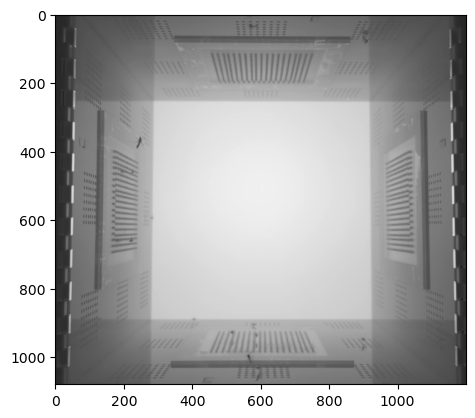

In [25]:
# load an example background image to look at
vid_dead_fn = "video_20260410_162723_0180.mp4"
dead_image_path = Path(vid_root) / "20260410" / "backgrounds_test" / vid_dead_fn.replace('.mp4', '.png')
dead_image = cv.imread(str(dead_image_path))

plt.imshow(dead_image, cmap='gray', vmin=0, vmax=255)

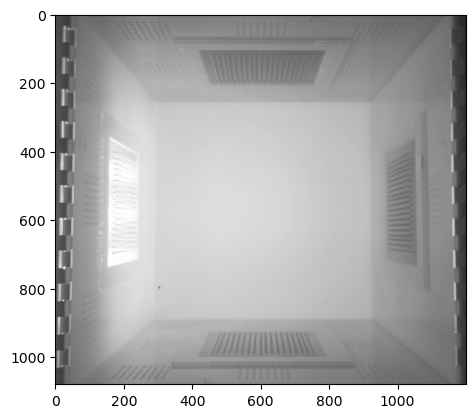

In [21]:
# bg
plt.imshow(bg, cmap='gray', vmin=0, vmax=255)

## Troubleshoot tracking

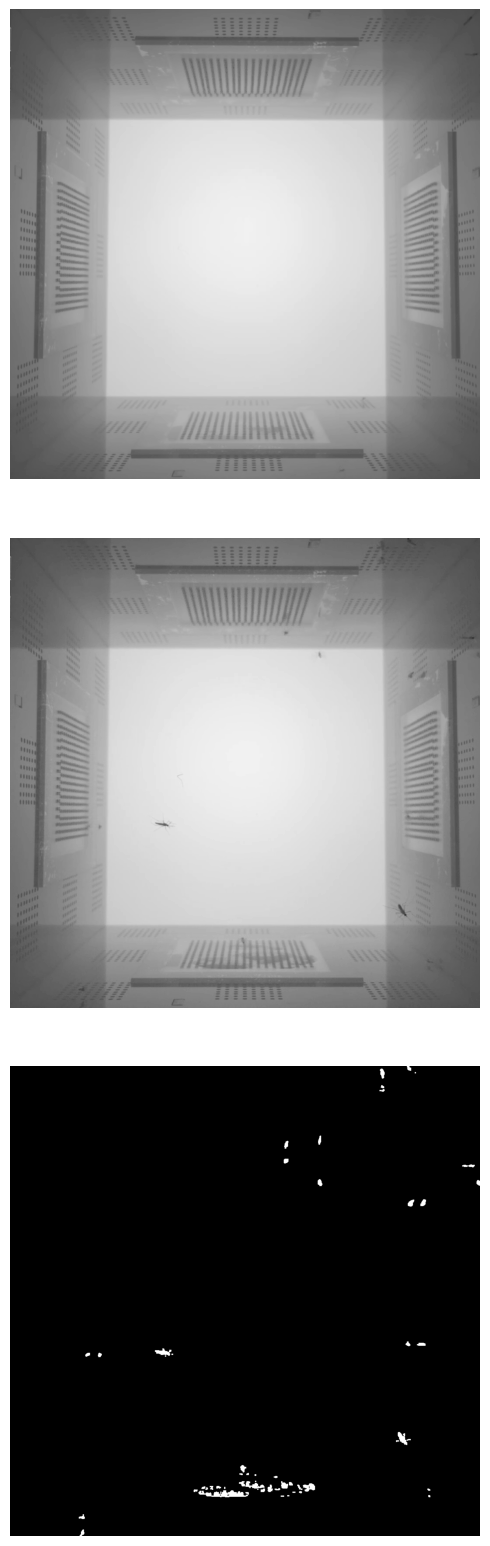

In [225]:
frame_crop_gray = cv.cvtColor(frame_crop, cv.COLOR_BGR2GRAY)
# frame_crop_gray_inv = cv.bitwise_not(frame_crop_gray)

# # subtract off static background
# # fg = cv.subtract(frame_crop_gray_inv, bg_gray_inv_crop)
# fg = cv.absdiff(frame_crop_gray_inv, bg_gray_inv_crop)

fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(5, 16))
ax0.imshow(bg_gray_inv_crop, cmap='gray_r', vmin=0, vmax=255)
ax1.imshow(frame_crop_gray, cmap='gray', vmin=0, vmax=255)
ax2.imshow(fg_mask, cmap='gray', vmin=0, vmax=255)

ax0.axis('off')
ax1.axis('off')
ax2.axis('off')
fig.tight_layout()

(array([0.19046235, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.0009439 ]),
 array([  0.        ,   5.2244898 ,  10.44897959,  15.67346939,
         20.89795918,  26.12244898,  31.34693878,  36.57142857,
         41.79591837,  47.02040816,  52.24489796,  57.46938776,
         62.69387755,  67.91836735,  73.14285714,  78.36734694,
         83.59183673,  88.81632653,  94.04081633,  99.26530612,
        10

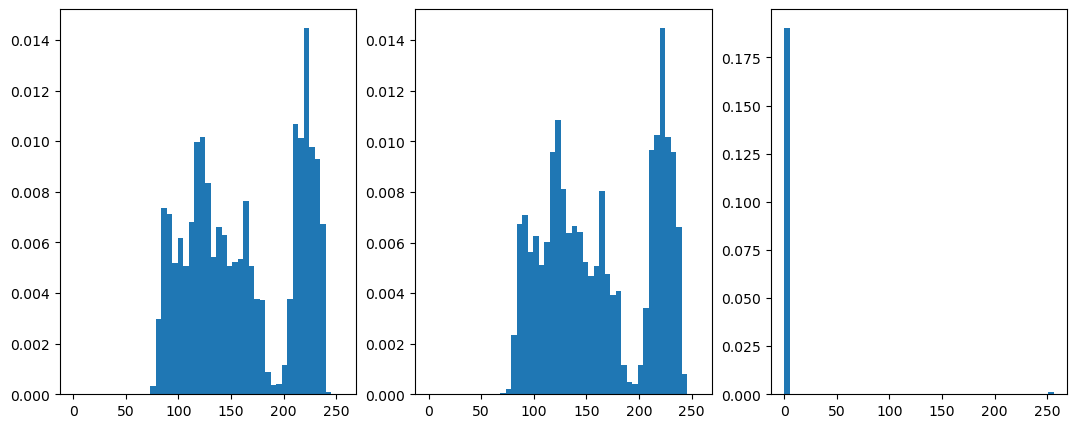

In [232]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(13, 5))
ax0.hist(255 - bg_gray_inv_crop.ravel(), bins=np.linspace(0,256), density=True)
ax1.hist(frame_crop_gray.ravel(), bins=np.linspace(0,256), density=True)
ax2.hist(fg_mask.ravel(), bins=np.linspace(0,256), density=True)

# ax0.axis('off')
# ax1.axis('off')
# ax2.axis('off')
# fig.tight_layout()

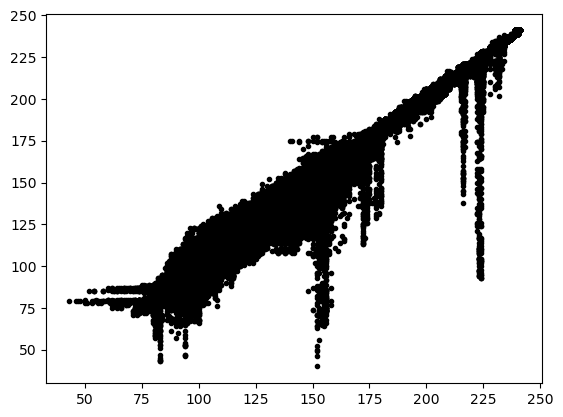

In [233]:
plt.plot(255 - bg_gray_inv_crop.ravel(), frame_crop_gray.ravel(), 'k.')

In [239]:
from numpy.polynomial import Polynomial

p = Polynomial.fit(255 - bg_gray_inv_crop.ravel(), frame_crop_gray.ravel(), 1)
print(p)

142.76486898 - 98.59785399 x


In [240]:
np.max(bg_gray_inv_crop)

212

In [241]:
np.max(frame_crop_gray)

241

In [122]:
# Check mean pixel value over time
mean_pix = list()
cap = cv.VideoCapture(str(vid_path_full))

frame_number = 0
while cap.isOpened():
    ret, frame = cap.read()
    
    # if frame is read correctly ret is True
    if not ret:
        print("Can't receive frame (stream end?). Exiting ...")
        break

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    mean_val, _, _, _ = cv.mean(gray)
    mean_pix.append(mean_val)
    
    frame_number +=1

    if frame_number > 500:
        break
    # if (frame_number % 100) == 0:
    #     gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    #     mean_pix.append(cv.mean(gray))
    #     print(frame_number)
 
cap.release()
cv.destroyAllWindows()

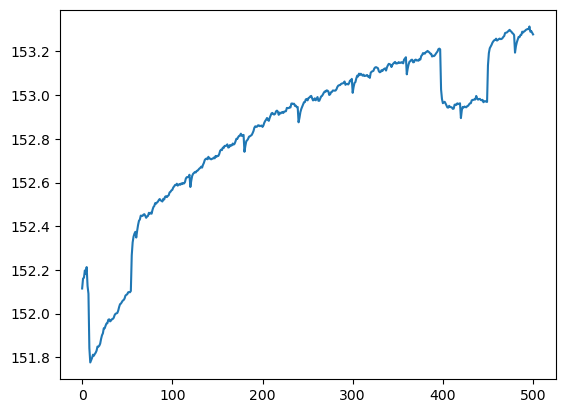

In [123]:
plt.plot(np.asarray(mean_pix))

## Side note: let's see if we can look at temp data from Theo's analysis

In [9]:
# path to data
temp_data_path = r'D:\buzzwatch_analysis\01_testing\cage_01\batch_03_drosophila_test\temp_data'
temp_data_fn = 'temp_data_video_20260323_170502_0000.pkl'

temp_path_full = Path(temp_data_path) / temp_data_fn
print(temp_path_full)


D:\buzzwatch_analysis\01_testing\cage_01\batch_03_drosophila_test\temp_data\temp_data_video_20260323_170502_0000.pkl


In [10]:
# try to add buzzwatch_data_analysis module so we can read data
sys.path.insert(1, r"C:\Users\samcw\Documents\PythonScripts\buzzwatch-analysis")
import buzzwatch_data_analysis

In [11]:
# open
temp_data = pd.read_pickle(temp_path_full)
# with open(temp_path_full, 'rb') as handle:
#     temp_data = pickle.load(handle)
    

In [12]:
len(temp_data.moving_objects)


32340

[(836.5, 806.0),
 (780.5, 778.5),
 (916.5, 628.0),
 (1126.5, 517.5),
 (672.5, 502.5),
 (1208.5, 963.5),
 (572.5, 524.5)]

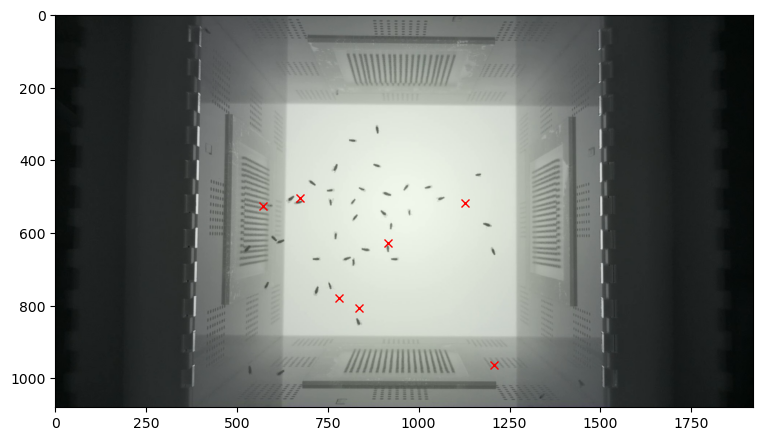

In [25]:
# do the coordinates in "moving_objects" correspond to flies?
test_frame = 1000

# get coordinates for this frame
coords = temp_data.moving_objects[400]

# get image for this frame
cap = cv.VideoCapture(str(vid_path_full))
cap.set(cv.CAP_PROP_POS_FRAMES, frame_number-1)
ret, frame = cap.read()
cap.release()
# cv.destroyAllWindows()

# visualize
fig, ax = plt.subplots(figsize=(9,9))

ax.imshow(frame)

for pt in coords:
    ax.plot(pt[0], pt[1], 'rx')

In [21]:
coords

[(836.5, 806.0),
 (780.5, 778.5),
 (916.5, 628.0),
 (1126.5, 517.5),
 (672.5, 502.5),
 (1208.5, 963.5),
 (572.5, 524.5)]

## Scratch

In [ ]:
# TEMP just get a single frame and save it
cap = cv.VideoCapture(str(vid_path_full))
     
ret, frame = cap.read()

# if frame is read correctly ret is True
if not ret:
    print("Can't receive frame (stream end?). Exiting ...")

# convert to grayscale
gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
cv.imwrite(r"C:\Users\samcw\OneDrive\Desktop\single_frame.png", gray)

# release video capture
cap.release()